#### EDA on movies_popular_pre2010 dataset

load data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

popmov = pd.read_csv("../../data/movies_popular_pre2010.csv")

popmov.head()

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
0,6,"10,000 B.C.",A young outcast from a primitive tribe is forc...,PG-13,"Action & Adventure, Classics, Drama",Roland Emmerich,2008-03-07,2008-06-24,109.0,8,148,37.0,411087.0,2008
1,51,Aliens,"Big-budget special effects, swiftly paced acti...",R,"Action & Adventure, Horror, Science Fiction & ...",James Cameron,1986-07-18,1999-06-01,138.0,99,72,94.0,429158.0,1986
2,85,The Happening,"The Happening' is a lightning-paced, heart-pou...",R,"Drama, Mystery & Suspense, Science Fiction & F...",M. Night Shyamalan,2008-06-11,2008-10-07,90.0,18,179,24.0,370131.0,2008
3,144,The Box,Norma and Arthur Lewis are a suburban couple w...,PG-13,"Horror, Mystery & Suspense, Science Fiction & ...",Richard Kelly,2009-11-06,2010-02-23,116.0,44,155,24.0,359067.0,2009
4,94,Disney's A Christmas Carol,Ebenezer Scrooge begins the Christmas holiday ...,PG,"Animation, Drama, Kids & Family, Science Ficti...",Robert Zemeckis,2009-11-06,2010-11-16,96.0,53,197,58.0,776113.0,2009


#### Movie Rating Analysis

What percent of movies fall under each type of rating (R, PG-13, etc.)?

In [4]:
# Check for missing values in the rating column
popmov['rating'].isna().sum()

0

In [6]:
# counts and percentages by rating
rating_counts = popmov["rating"].value_counts().sort_index()
rating_percent = rating_counts / len(popmov) * 100

rating_summary = pd.DataFrame({
    "count": rating_counts,
    "percent": rating_percent.round(1)
})

rating_summary

,count,percent
rating,,
G,41,4.9
PG,170,20.2
PG-13,368,43.7
R,264,31.3


Among popular pre-2010 movies, nearly half are PG-13 (about 44%) and about a third are R-rated (31%), while PG makes up around 20% and G only about 5%. So this “popular” subset is heavily skewed toward teen and adult audiences, with relatively few purely family-oriented (G) titles.

Create a visualization that shows for each rating (R, PG-13, etc.), the average critic rating and the average audience rating.

In [7]:
# average critic and audience rating for each rating category
rating_means = (
    popmov.groupby("rating")[["critic_rating", "audience_rating"]]
      .mean()
      .sort_index()
)

rating_means

,critic_rating,audience_rating
rating,,
G,73.512195,73.195122
PG,59.652941,65.870588
PG-13,49.926630,63.086957
R,61.121212,70.821970


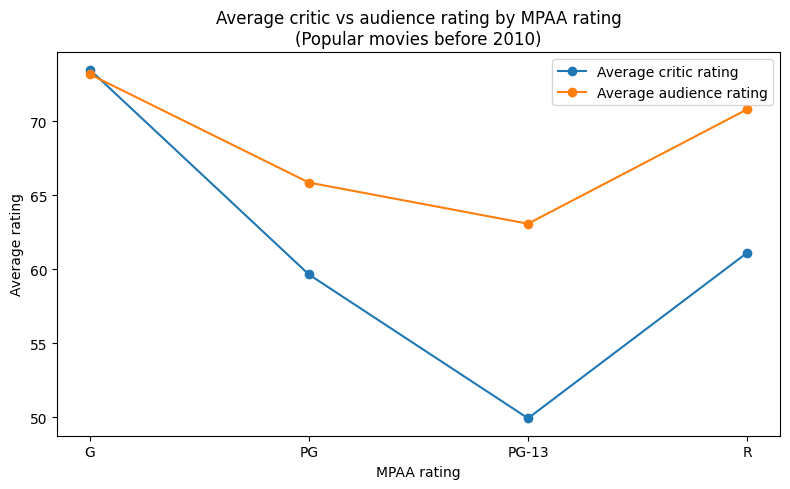

In [9]:
plt.figure(figsize=(8, 5))

x = range(len(rating_means))
plt.plot(x, rating_means["critic_rating"], marker="o", label="Average critic rating")
plt.plot(x, rating_means["audience_rating"], marker="o", label="Average audience rating")

plt.xticks(x, rating_means.index)
plt.xlabel("MPAA rating")
plt.ylabel("Average rating")
plt.title("Average critic vs audience rating by MPAA rating\n(Popular movies before 2010)")
plt.legend()
plt.tight_layout()
plt.show()

For popular pre-2010 movies, G-rated films have the highest average critic and audience scores among the four rating categories. PG and especially PG-13 movies tend to have lower average critic scores than G and R movies. Across all categories, audience ratings are consistently higher than critic ratings, with the biggest differences for PG-13 and R, suggesting that viewers are generally more enthusiastic about these films than critics are.

#### Pair Plot & Insights

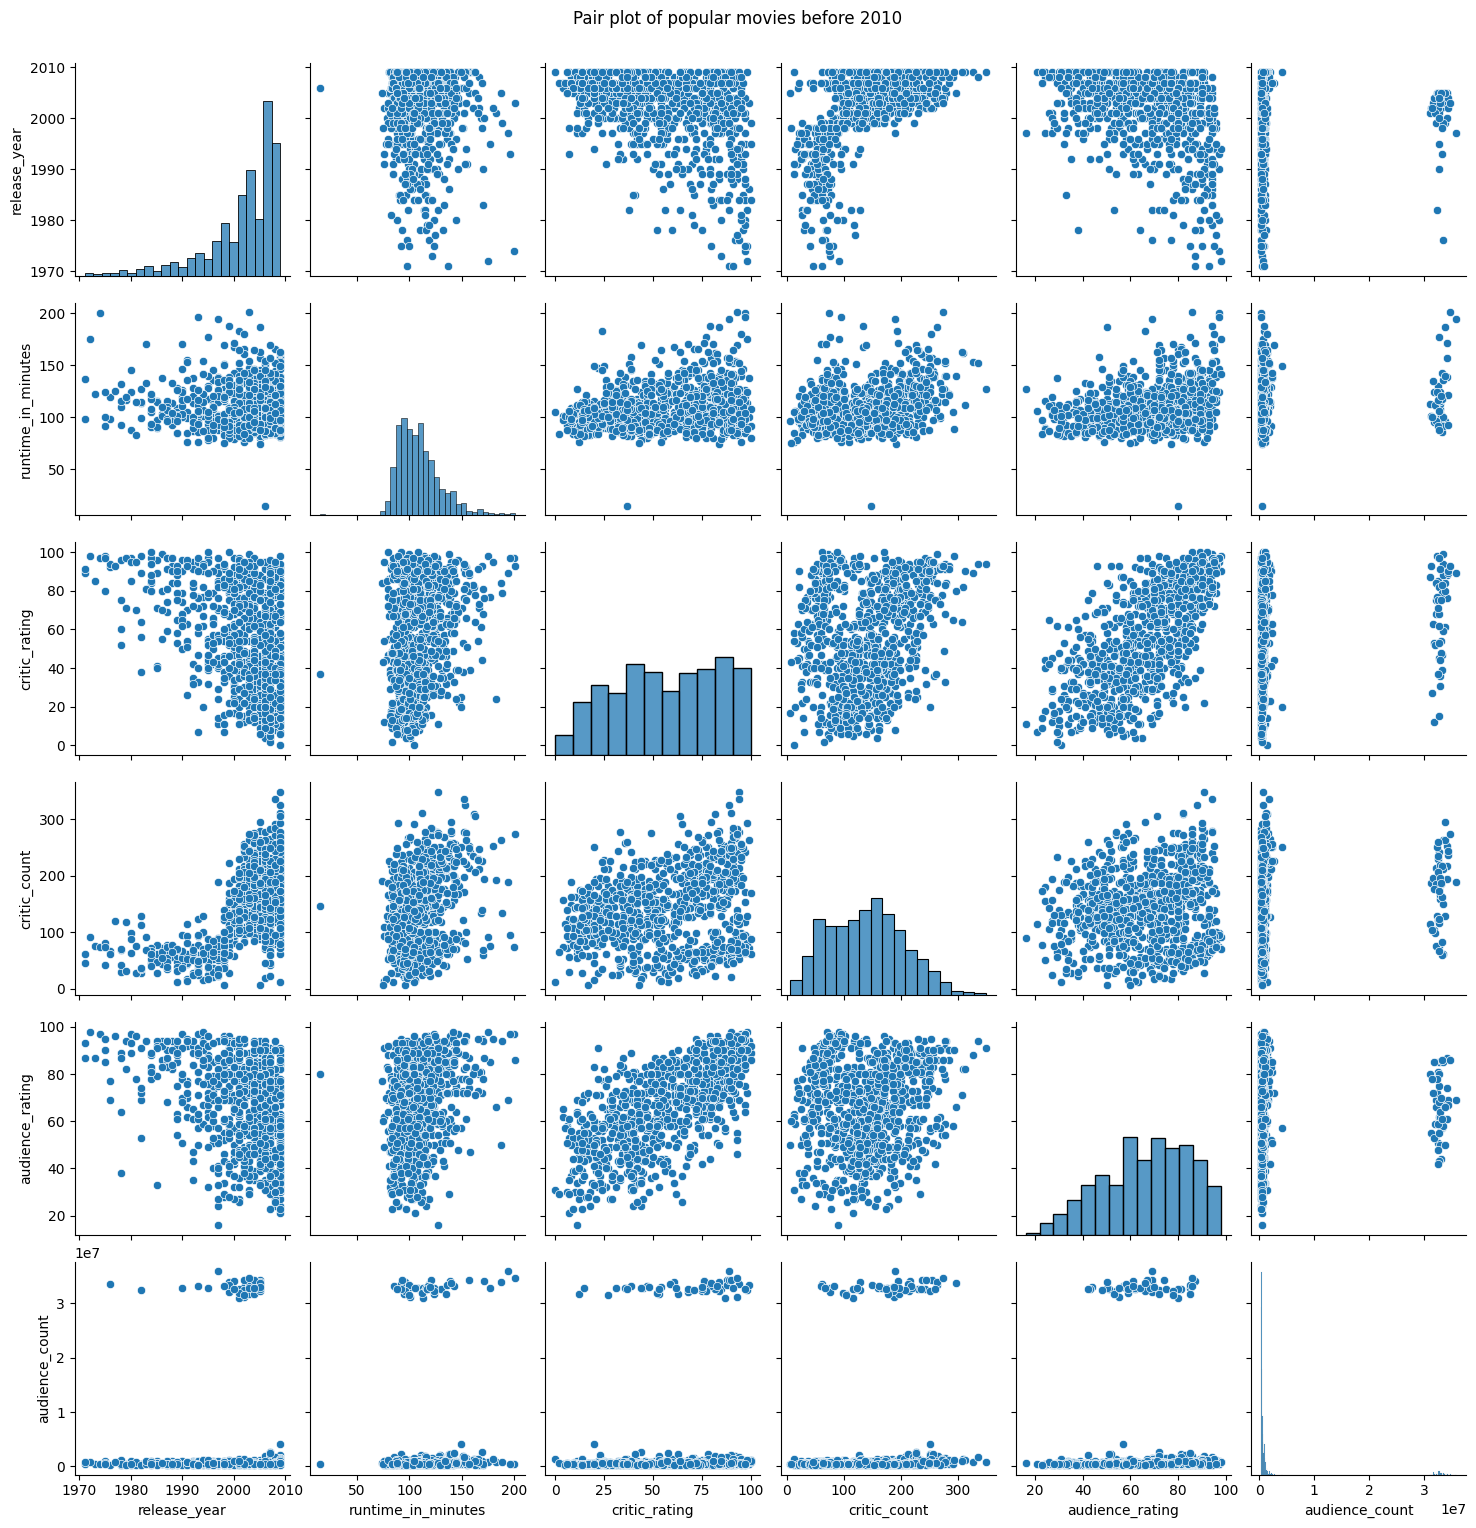

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = [
    "release_year",
    "runtime_in_minutes",
    "critic_rating",
    "critic_count",
    "audience_rating",
    "audience_count",
]

sns.pairplot(popmov[num_cols], diag_kind="hist")
plt.suptitle("Pair plot of popular movies before 2010", y=1.02)
plt.show()

1. Critic vs audience agreement.

The points in the critic_rating vs audience_rating panel mostly form an upward cloud, which means higher critic scores usually go with higher audience scores. So in general, critics and audiences tend to agree on which movies get higher ratings and which get lower ratings.

2. Audience review counts show very uneven popularity.

The panels involving audience_count show two clear tiers: a large cluster of movies with relatively few audience reviews and a much smaller group of blockbusters with extremely high counts. The audience_count histogram is extremely right-skewed, which means most movies in this popular subset still have modest audience reach, while a small number of titles attract a huge number of reviews.

3. Limited relationship with runtime or year.

The panels involving runtime_in_minutes or release_year against the rating variables show a wide scatter with no strong shape. That suggests that, within this popular-movie subset, how long a movie is or exactly when it was released doesn’t have a clear, simple relationship with its critic or audience rating.

#### More Insights

1. Genre composition of popular pre-2010 movies

In [15]:
# split multi-genre strings
genre_counts = (
    popmov["genre"]
      .str.split(",")
      .explode()
      .str.strip()
      .value_counts()
)

genre_counts.head(10)

genre
Comedy                       388
Drama                        338
Action & Adventure           335
Science Fiction & Fantasy    209
Mystery & Suspense           202
Kids & Family                140
Horror                       119
Romance                      114
Animation                     68
Musical & Performing Arts     29
Name: count, dtype: int64

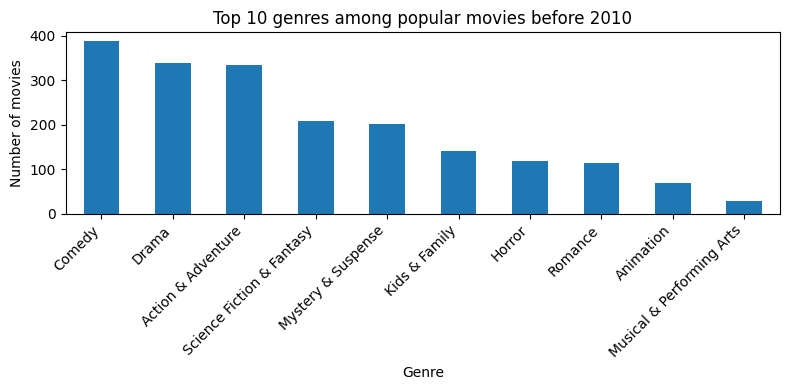

In [16]:
plt.figure(figsize=(8,4))
genre_counts.head(10).plot(kind="bar")
plt.xlabel("Genre")
plt.ylabel("Number of movies")
plt.title("Top 10 genres among popular movies before 2010")
plt.xticks(rotation=45, ha="right")  
plt.tight_layout()
plt.show()

The top 10 genres among popular pre-2010 movies are led by Comedy, Drama, and Action & Adventure, each with well over 300 titles. Genres like Science Fiction & Fantasy and Mystery & Suspense are also common but appear less frequently, while Animation and Musical & Performing Arts are much rarer. Overall, this suggests that the dataset is heavily skewed toward mainstream comedic and dramatic films with action elements.

2. Directors with consistently high critic ratings

In [19]:
# directors with at least 3 popular movies
dir_stats = (
    popmov.groupby("directors")
          .agg(avg_critic=("critic_rating", "mean"),
               movie_count=("movie_id", "count"))
          .query("movie_count >= 3")
          .sort_values("avg_critic", ascending=False)
)

dir_stats.head(10)

,avg_critic,movie_count
directors,,
James Cameron,92.600000,5
"John Musker, Ron Clements",90.666667,3
Danny Boyle,89.000000,3
Stanley Kubrick,88.333333,3
Quentin Tarantino,88.200000,5
Francis Ford Coppola,87.666667,3
Clint Eastwood,87.666667,3
Martin Scorsese,86.666667,3
Christopher Nolan,86.500000,4


Directors with at least three popular movies in the dataset show some clear standouts with very high average critic ratings. Names like James Cameron, Danny Boyle, Stanley Kubrick, Quentin Tarantino, Francis Ford Coppola, Clint Eastwood, Martin Scorsese, Christopher Nolan, and Sam Raimi all have average critic scores in the mid-80s to 90s, indicating consistently strong critical reception across multiple films.

3. Critics vs audiences: who is harsher?

In [20]:
# difference = audience score minus critic score
popmov["aud_minus_crit"] = popmov["audience_rating"] - popmov["critic_rating"]

popmov["aud_minus_crit"].describe()

count    843.000000
mean      10.021352
std       19.064138
min      -47.000000
25%       -3.000000
50%        8.000000
75%       22.500000
max       69.000000
Name: aud_minus_crit, dtype: float64

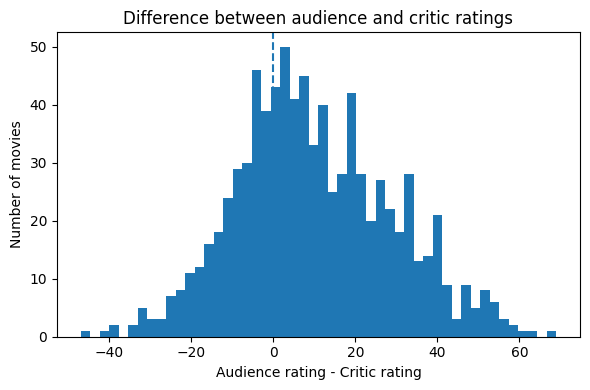

In [24]:
plt.figure(figsize=(6,4))
plt.hist(popmov["aud_minus_crit"], bins=50)
plt.axvline(0, linestyle="--")
plt.xlabel("Audience rating - Critic rating")
plt.ylabel("Number of movies")
plt.title("Difference between audience and critic ratings")
plt.tight_layout()
plt.show()

The distribution of aud_minus_crit (audience rating − critic rating) is centered above zero, with a mean around 10 and a median of 8. This indicates that, for most popular pre-2010 movies, audience scores are noticeably higher than critic scores (viewers tend to be more generous than critics). However, the spread from about −47 to +69 shows that there are still some films critics prefer and others that audiences like much more.